In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df= pd.read_csv("top-5000-youtube-channels.csv")
print(df)

# 1. Display All Rows Except the Last 5 rows Using Head Method

In [ ]:
df.head(-5)

# 2. Display All Rows Except the First 5 Rows Using Tail Method

In [ ]:
df.tail(-5)

# 3. Find Shape of Our Dataset (Number of Rows And Number of Columns)


In [ ]:
df.shape
print(df.shape[0],'Rows')
print(df.shape[1],"columns")

# 4. Get Information About Our Dataset Like Total Number Rows, Total Number of Columns, Datatypes of Each  Column And Memory Requirement

In [ ]:
df.info()

# 5. Get Overall Statistics About The Dataframe

In [ ]:
pd.options.display.float_format = '{:.3f}'.format

df.describe(include="all")


# 6. Data Cleaning  (Replace '--'  to NaN)

Manually

In [ ]:
for x in df.columns:
    if df[x].astype(str).str.contains("--").any():
        df[x]=df[x].replace("--",np.nan)

print(df)


Simple Method

In [ ]:
df= df.replace("--",np.nan,regex= True)
df.head(25)


# 7. Check Null Values In The Dataset

In [ ]:
print(df.isnull().sum())

per_missing = df.isnull().sum() *100 / len(df)
per_missing

In [ ]:
sns.heatmap(df.isnull())

plt.xticks(rotation=45)
plt.show()


df.dropna(axis=0,inplace = True)

# 8. Data Cleaning [ Rank Column ]

In [ ]:
df["Rank"]=df["Rank"].str[0:-2]
df["Rank"] = df["Rank"].str.replace(',',"")


In [ ]:

df["Rank"]=pd.to_numeric(df["Rank"],errors= 'coerce')

print(df.tail())
print(df["Rank"].dtypes)

print(df["Rank"].isnull().sum())


# 9. Data Cleaning [ Video Uploads & Subscribers ]

In [ ]:
df.head()
df["Subscribers"]= pd.to_numeric(df["Subscribers"],errors='coerce').astype(int)
df["Video views"]= pd.to_numeric(df["Video views"],errors='coerce')

print(df.dtypes)

df.isnull().sum()

df.dropna(inplace=True)
print(df.isnull().sum())


# 10. Data Cleaning [ Grade Column ]

In [ ]:

df.head(10)
df["Grade"].unique()



In [ ]:
df["Encoded grade"]=df["Grade"].map({"A++ ":5,"A+ ":4,"A ":3,"A- ":2,"B+ ":1})
df.head(20)

# 11. Find Average Views For Each Channel

In [ ]:
df.columns
# df["Channel name"]

In [ ]:
df.groupby("Channel name")["Video views"].mean().sort_values(ascending=False)

# 12. Find Out Top Five Channels With Maximum Number of Video Uploads

In [ ]:
df.columns

In [ ]:
df["Video Uploads"]=pd.to_numeric(df["Video Uploads"],errors='coerce')

df.groupby("Channel name")["Video Uploads"].mean().head(5).sort_values(ascending=False)

# 13. Find Correlation Matrix

                Rank  Video Uploads  Subscribers  Video views  Encoded grade
Rank           1.000         -0.073       -0.383       -0.403         -0.865
Video Uploads -0.073          1.000        0.011        0.088          0.089
Subscribers   -0.383          0.011        1.000        0.791          0.429
Video views   -0.403          0.088        0.791        1.000          0.477
Encoded grade -0.865          0.089        0.429        0.477          1.000


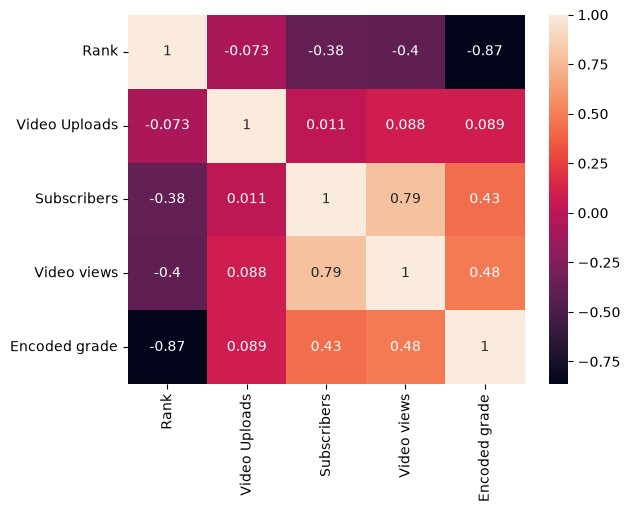

In [215]:
corr= df.corr(numeric_only=True)
print(corr)
sns.heatmap(corr,annot=True)
plt.show()

# 14.  Which Grade Has A Maximum Number of Video Uploads?

In [213]:
df.columns

Index(['Rank', 'Grade', 'Channel name', 'Video Uploads', 'Subscribers',
       'Video views', 'Encoded grade'],
      dtype='str')

In [ ]:
df.head()
df.sort_values(by="Video Uploads",ascending=False).head(1)["Grade"]

# 15.Which Grade Has The Highest Average Views?

In [ ]:
zi= df.groupby("Grade")["Video views"].mean().sort_values(ascending=False).head(1)
zi



In [ ]:
sns.barplot(x="Grade",y="Video views",data=df)
plt.show()

# 16.  Which Grade Has The Highest Number of Subscribers? 


In [ ]:
df.groupby("Grade")["Subscribers"].max().sort_values(ascending=False).head(1)

# 17. Which Grade Has The Highest Video Views?

In [214]:
df.groupby("Grade")["Video views"].max().sort_values(ascending=False).head(1)

Grade
A++     47548839843
Name: Video views, dtype: int64